<a href="https://colab.research.google.com/github/kristinalatish/machine-learning/blob/main/%D0%9B%D1%96%D0%BD%D1%96%D0%B9%D0%BD%D0%B0_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_%D0%9B%D0%B0%D1%82%D0%B8%D1%88_%D0%A4%D0%86%D0%A23_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тренувальний ноутбук: лінійна регресія та регуляризація

**Виконала:** Латиш Крістіна Андріївна, група ФІТ 3-12, № за списком 15

**Курс:** Машинне навчання  
**Тема:** Linear Regression, Ridge, Lasso, Elastic Net

Цей ноутбук відповідає лекції про лінійну регресію та побудований як практичне продовження теоретичного матеріалу. У прикладах послідовно розглядаються проста й множинна лінійна регресія, метрики, залишки, недонавчання і перенавчання, L1/L2-регуляризація, Ridge, Lasso, Elastic Net, масштабування, крос-валідація, `GridSearchCV`, `Pipeline`, `ColumnTransformer` та навчальні криві.

У ноутбуці є два типи комірок:

- **Приклад** — готовий код, який потрібно виконати, проаналізувати та пояснити.
- **Самостійне завдання** — окрема кодова комірка з позначкою `TODO`. Її потрібно заповнити власноруч. Готового розв'язку в ноутбуці немає.

Рекомендація: виконувати комірки послідовно зверху вниз і після кожного блоку формулювати короткий висновок своїми словами.

## 0. Імпорт бібліотек і налаштування середовища

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Середовище готове до роботи.')

Середовище готове до роботи.


## 1. Проста лінійна регресія

Для однієї ознаки модель має вигляд

$$
\hat y = b_0 + b_1x.
$$

Тут $b_0$ — вільний член, а $b_1$ показує, на скільки одиниць у середньому змінюється прогноз $\hat y$ при збільшенні $x$ на одну одиницю.

Нижче згенеруємо дані, у яких істинна залежність приблизно дорівнює $y=5+2.4x$, але спостереження містять випадковий шум.

Вільний член b0: 4.907
Коефіцієнт b1: 2.451


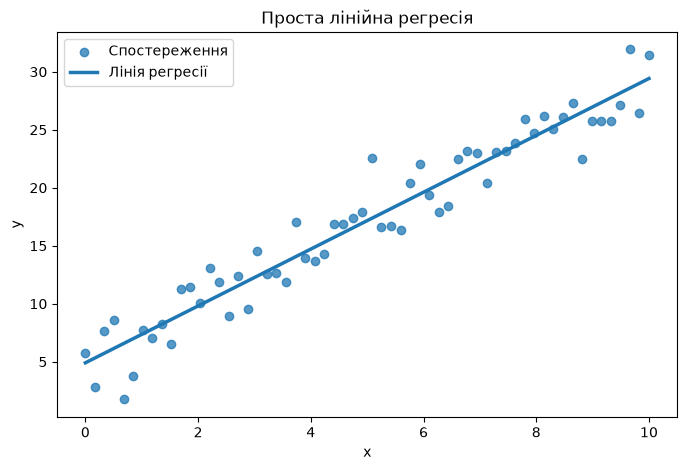

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)

X_simple = np.linspace(0, 10, 60).reshape(-1, 1)
y_simple = 5 + 2.4 * X_simple.ravel() + rng.normal(0, 2.5, size=len(X_simple))

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)
y_simple_pred = simple_model.predict(X_simple)

print(f'Вільний член b0: {simple_model.intercept_:.3f}')
print(f'Коефіцієнт b1: {simple_model.coef_[0]:.3f}')

plt.figure(figsize=(8, 5))
plt.scatter(X_simple.ravel(), y_simple, alpha=0.75, label='Спостереження')
plt.plot(X_simple.ravel(), y_simple_pred, linewidth=2.5, label='Лінія регресії')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Проста лінійна регресія')
plt.legend()
plt.show()

**Що потрібно побачити.** Коефіцієнт нахилу має бути близьким до 2.4, але не обов'язково дорівнювати йому точно, оскільки дані містять шум. `fit()` оцінює параметри за навчальними даними, а `predict()` лише обчислює прогноз для заданих значень ознак.

### Самостійне завдання 1

1. Створіть новий масив `X_new` зі значеннями 2, 5 і 8.
2. Отримайте прогнози моделі.
3. Виведіть таблицю з колонками `x` та `prediction`.
4. Одним реченням поясніть зміст отриманого коефіцієнта `b1`.

In [ ]:
X_new = np.array([2, 5, 8]).reshape(-1, 1)
y_new = simple_model.predict(X_new)

result1 = pd.DataFrame()
result1['x'] = [2, 5, 8]
result1['prediction'] = y_new.round(2)
print(result1)

# b1 показує, на скільки в середньому зростає прогноз y, якщо x збільшити на 1
print('b1 =', round(simple_model.coef_[0], 2), '-> при x + 1 прогноз y зростає приблизно на 2.45')

   x  prediction
0  2        9.81
1  5       17.16
2  8       24.52
b1 = 2.45 -> при x + 1 прогноз y зростає приблизно на 2.45


## 2. Метод найменших квадратів і ручний розрахунок коефіцієнтів

Для простої регресії коефіцієнт нахилу можна обчислити без готової моделі:

$$
b_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2},
\qquad
b_0 = \bar y-b_1\bar x.
$$

Чисельник у формулі для $b_1$ відображає спільну зміну $x$ і $y$, а знаменник — варіативність самої ознаки $x$. Після знаходження нахилу вільний член підбирається так, щоб пряма проходила через точку $(\bar x, \bar y)$.

In [ ]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([3.0, 5.2, 6.8, 9.1, 10.9])

x_bar = x.mean()
y_bar = y.mean()

b1_manual = ((x - x_bar) * (y - y_bar)).sum() / ((x - x_bar) ** 2).sum()
b0_manual = y_bar - b1_manual * x_bar

model_check = LinearRegression().fit(x.reshape(-1, 1), y)

print(f'Ручний розрахунок: b0={b0_manual:.4f}, b1={b1_manual:.4f}')
print(f'scikit-learn:     b0={model_check.intercept_:.4f}, b1={model_check.coef_[0]:.4f}')

Ручний розрахунок: b0=1.0900, b1=1.9700
scikit-learn:     b0=1.0900, b1=1.9700


### Самостійне завдання 2

Використайте масиви `x2 = [2, 4, 6, 8, 10]` та `y2 = [7, 11, 16, 19, 25]`. Власноруч обчисліть `b0` і `b1` за формулами, а потім перевірте результат за допомогою `LinearRegression`.

In [ ]:
x2 = np.array([2, 4, 6, 8, 10])
y2 = np.array([7, 11, 16, 19, 25])

# середні значення
mx = np.mean(x2)
my = np.mean(y2)
print('середнє x:', mx, ' середнє y:', my)

# коефіцієнти за формулами
b1_hand = np.sum((x2 - mx) * (y2 - my)) / np.sum((x2 - mx) ** 2)
b0_hand = my - b1_hand * mx
print('b1 =', round(b1_hand, 2))
print('b0 =', round(b0_hand, 2))

# перевірка
check = LinearRegression().fit(x2.reshape(-1, 1), y2)
print('перевірка sklearn: b1 =', round(check.coef_[0], 2), ' b0 =', round(check.intercept_, 2))

середнє x: 6.0  середнє y: 15.6
b1 = 2.2
b0 = 2.4
перевірка sklearn: b1 = 2.2  b0 = 2.4


## 3. Множинна лінійна регресія

У випадку кількох ознак модель має вигляд

$$
\hat y = b_0+b_1x_1+b_2x_2+\dots+b_px_p.
$$

Коефіцієнт $b_j$ інтерпретується як зміна прогнозу при збільшенні ознаки $x_j$ на одну одиницю **за інших рівних умов**, тобто при фіксованих значеннях інших ознак.

Для практики використаємо вбудований набір `diabetes`, тому ноутбук не потребує завантаження даних з Інтернету.

In [ ]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

print('Розмір X:', X.shape)
print('Розмір y:', y.shape)
display(X.head())

Розмір X: (442, 10)
Розмір y: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [ ]:
multi_model = LinearRegression()
multi_model.fit(X, y)

coef_table = pd.DataFrame({
    'feature': X.columns,
    'coefficient': multi_model.coef_
}).sort_values('coefficient', key=np.abs, ascending=False)

display(coef_table)
print(f'Intercept: {multi_model.intercept_:.3f}')

,feature,coefficient
4,s1,-792.175639
8,s5,751.273700
2,bmi,519.845920
5,s2,476.739021
3,bp,324.384646
1,sex,-239.815644
7,s4,177.063238
6,s3,101.043268
9,s6,67.626692
0,age,-10.009866


Intercept: 152.133


Зверніть увагу: великий за модулем коефіцієнт не завжди означає, що ознака є «найважливішою». Порівняння коефіцієнтів залежить від масштабу ознак та їх взаємної кореляції.

## 4. Train/test та наївний baseline

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)



`DummyRegressor` не використовує закономірності в ознаках і в цьому прикладі прогнозує середнє значення цільової змінної з train. Якщо реальна модель не перевершує такий baseline, необхідно переглянути ознаки, постановку задачі або сам алгоритм.

## 5. Метрики якості регресії

У лекції розглядалися MAE, MSE, RMSE та $R^2$. Вони відповідають на різні питання.

- **MAE** показує середню абсолютну величину помилки.
- **MSE** сильніше штрафує великі помилки через піднесення залишку до квадрата.
- **RMSE** є коренем з MSE і вимірюється в тих самих одиницях, що й цільова змінна.
- **$R^2$** порівнює модель із прогнозом середнім значенням цільової змінної. На нових даних він може бути від'ємним.

In [ ]:
def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE': (np.abs(y_true - y_pred) / y_true).mean() * 100
    }

metrics_baseline = regression_metrics(y_test, baseline_pred)
metrics_linear = regression_metrics(y_test, linear_pred)

pd.DataFrame([metrics_baseline, metrics_linear], index=['DummyRegressor', 'LinearRegression'])

,MAE,MSE,RMSE,R2,MAPE
DummyRegressor,64.006461,5361.533457,73.222493,-0.011963,62.791796
LinearRegression,42.794095,2900.193628,53.853446,0.452603,37.499826


### Самостійне завдання 3

Обчисліть MAE, RMSE і $R^2$ окремо, **не використовуючи** функцію `regression_metrics`. Порівняйте `DummyRegressor` і `LinearRegression`. У Markdown-комірці нижче поясніть, яка модель краща і чому не варто робити висновок лише за однією метрикою.

In [ ]:
print('DummyRegressor')
print('MAE:', round(mean_absolute_error(y_test, baseline_pred), 2))
print('RMSE:', round(root_mean_squared_error(y_test, baseline_pred), 2))
print('R2:', round(r2_score(y_test, baseline_pred), 3))

print()
print('LinearRegression')
print('MAE:', round(mean_absolute_error(y_test, linear_pred), 2))
print('RMSE:', round(root_mean_squared_error(y_test, linear_pred), 2))
print('R2:', round(r2_score(y_test, linear_pred), 3))

DummyRegressor
MAE: 64.01
RMSE: 73.22
R2: -0.012

LinearRegression
MAE: 42.79
RMSE: 53.85
R2: 0.453


**Ваш висновок:**
Метрики порахувала окремо для кожної моделі.

| Модель | MAE | RMSE | R² |
|---|---|---|---|
| DummyRegressor | 64.01 | 73.22 | -0.012 |
| LinearRegression | 42.79 | 53.85 | 0.453 |

LinearRegression краща, бо вона використовує ознаки, а Dummy просто прогнозує середнє.

Дивитись на одну метрику мало: MAE показує середню помилку, RMSE більше штрафує великі промахи, а R² показує частку поясненого розкиду. Разом вони дають повнішу картину.

## 6. Залишки та діагностика моделі

Залишок для об'єкта визначається як

$$
e_i = y_i-\hat y_i.
$$

Якщо модель добре описує систематичну частину залежності, на графіку `prediction → residual` не повинно бути вираженої структури. Дуга може вказувати на нелінійність, а «воронка» — на зміну дисперсії помилки.

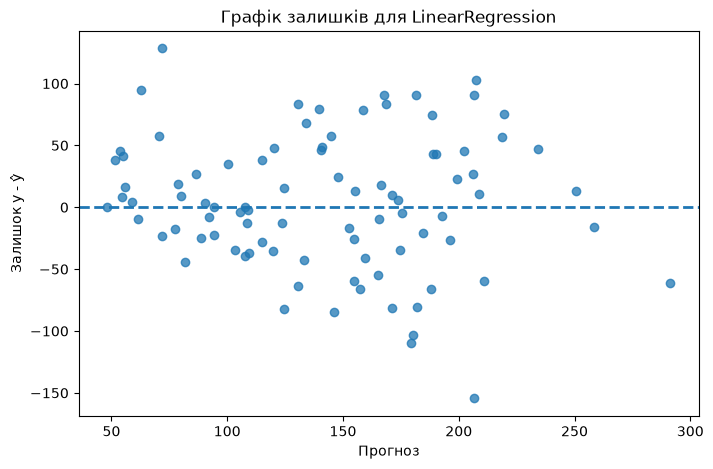

In [ ]:
residuals = y_test - linear_pred

plt.figure(figsize=(8, 5))
plt.scatter(linear_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle='--', linewidth=2)
plt.xlabel('Прогноз')
plt.ylabel('Залишок y - ŷ')
plt.title('Графік залишків для LinearRegression')
plt.show()

## 7. Недонавчання і перенавчання на поліноміальній регресії

Лінійна модель може недонавчатися, якщо реальна залежність нелінійна. Один зі способів збільшити гнучкість — створити поліноміальні ознаки. Але занадто високий ступінь полінома збільшує ризик перенавчання.

Порівняємо ступені 1, 4 і 15 на невеликій синтетичній вибірці.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
X_poly = np.sort(rng.uniform(-3, 3, 45)).reshape(-1, 1)
y_true_poly = np.sin(X_poly.ravel()) + 0.25 * X_poly.ravel()
y_poly = y_true_poly + rng.normal(0, 0.22, size=len(X_poly))

X_p_train, X_p_test, y_p_train, y_p_test = train_test_split(
    X_poly, y_poly, test_size=0.35, random_state=RANDOM_STATE
)

def fit_polynomial(degree):
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('reg', LinearRegression()),
    ])
    model.fit(X_p_train, y_p_train)
    train_pred = model.predict(X_p_train)
    test_pred = model.predict(X_p_test)
    return model, {
        'degree': degree,
        'train_rmse': root_mean_squared_error(y_p_train, train_pred),
        'test_rmse': root_mean_squared_error(y_p_test, test_pred),
    }

results = []
models_poly = {}
for degree in [1, 4, 15]:
    m, res = fit_polynomial(degree)
    models_poly[degree] = m
    results.append(res)

pd.DataFrame(results)

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,4,0.144969,0.203183
2,15,0.091024,0.244266


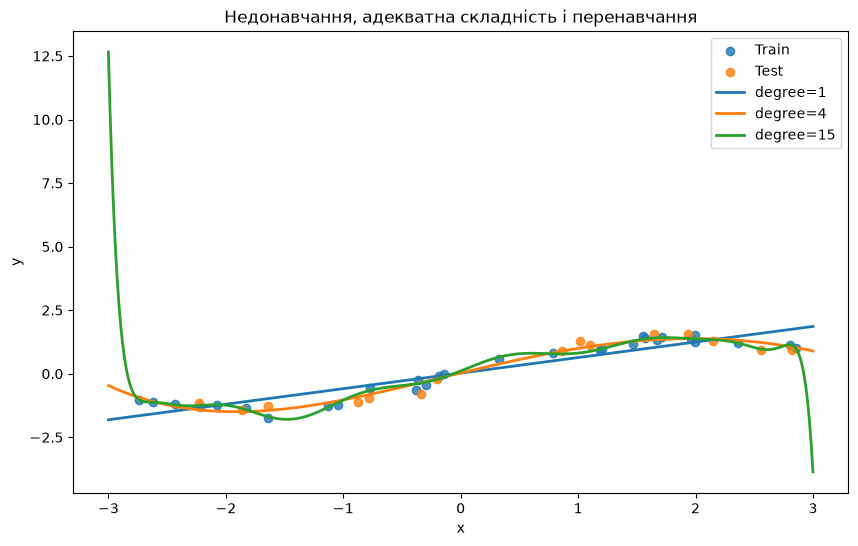

In [ ]:
grid = np.linspace(-3, 3, 400).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_p_train, y_p_train, label='Train', alpha=0.8)
plt.scatter(X_p_test, y_p_test, label='Test', alpha=0.8)

for degree in [1, 4, 15]:
    plt.plot(grid, models_poly[degree].predict(grid), linewidth=2, label=f'degree={degree}')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Недонавчання, адекватна складність і перенавчання')
plt.legend()
plt.show()

### Самостійне завдання 4

1. Додайте до порівняння ступені 2, 6 і 10.
2. Побудуйте таблицю `degree`, `train_rmse`, `test_rmse`.
3. Визначте ступінь із найменшим `test_rmse`.
4. Поясніть, чому мінімальна train-помилка не гарантує найкращої моделі.

In [ ]:
degrees = [1, 2, 4, 6, 10, 15]
rows4 = []
for d in degrees:
    model_d, res_d = fit_polynomial(d)
    rows4.append(res_d)

poly_df = pd.DataFrame(rows4)
display(poly_df.round(3))

print('Найкращий ступінь за test_rmse:', poly_df.sort_values('test_rmse').iloc[0]['degree'])

,degree,train_rmse,test_rmse
0,1,0.393,0.465
1,2,0.393,0.464
2,4,0.145,0.203
3,6,0.137,0.196
4,10,0.129,0.192
5,15,0.091,0.244


Найкращий ступінь за test_rmse: 10.0


**Висновок.**
Найменший test_rmse вийшов у ступеня 10 (0.192). Ступені 4 і 6 майже такі самі (0.203 і 0.196), тому можна взяти і простішу модель.

Ступені 1 і 2 недонавчаються, помилка велика і на train, і на test (близько 0.39 і 0.46).

У ступеня 15 найменша train-помилка (0.091), але test-помилка виросла до 0.244, це перенавчання. Модель добре запам'ятала train, але гірше працює на нових даних, тому обирати треба за test-помилкою, а не за train.

## 8. Регуляризація: загальна ідея

Коли модель має багато ознак або ознаки сильно корельовані, коефіцієнти можуть ставати нестабільними. Регуляризація додає до функції втрат штраф за великі коефіцієнти.

Для Ridge використовується L2-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p} b_j^2,
$$

для Lasso — L1-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p}|b_j|.
$$

Параметр $\alpha$ керує силою регуляризації. Якщо $\alpha=0$, штраф зникає. Надто велике $\alpha$ може надмірно стиснути коефіцієнти й спричинити недонавчання.

## 9. Чому перед Ridge, Lasso та Elastic Net потрібне масштабування

In [ ]:
# Штучно змінюємо масштаби кількох ознак, щоб побачити роль StandardScaler.
X_scaled_demo = X.copy()
X_scaled_demo['bmi'] = X_scaled_demo['bmi'] * 1000
X_scaled_demo['bp'] = X_scaled_demo['bp'] * 0.01

Xsd_train, Xsd_test, ysd_train, ysd_test = train_test_split(
    X_scaled_demo, y, test_size=0.2, random_state=RANDOM_STATE
)

ridge_no_scaling = Ridge(alpha=10.0).fit(Xsd_train, ysd_train)
ridge_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(Xsd_train, ysd_train)

print('Ridge без масштабування RMSE:', root_mean_squared_error(ysd_test, ridge_no_scaling.predict(Xsd_test)))
print('Ridge + StandardScaler RMSE:', root_mean_squared_error(ysd_test, ridge_pipeline.predict(Xsd_test)))

Ridge без масштабування RMSE: 62.25349241861679
Ridge + StandardScaler RMSE: 53.6262875688952


Штраф застосовується безпосередньо до коефіцієнтів. Якщо ознаки вимірюються в дуже різних масштабах, одна й та сама величина коефіцієнта не має однакового змісту. Тому `StandardScaler` зазвичай включають у `Pipeline` перед регуляризованою лінійною моделлю.

## 10. Ridge-регресія: L2-регуляризація

In [ ]:
ridge = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

print(regression_metrics(y_test, ridge_pred))

{'MAE': 42.81199941834889, 'MSE': 2892.0145657501735, 'RMSE': 53.7774540653439, 'R2': 0.454146520706982, 'MAPE': np.float64(37.44816405198748)}


## 11. Lasso: L1-регуляризація

In [ ]:
lasso = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(alpha=1.0, max_iter=20000)),
])

lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

lasso_coef = lasso.named_steps['reg'].coef_
print(regression_metrics(y_test, lasso_pred))
print('Кількість нульових коефіцієнтів:', np.sum(np.isclose(lasso_coef, 0)))

{'MAE': 42.80298373195777, 'MSE': 2824.568094049959, 'RMSE': 53.14666587896139, 'R2': 0.46687670944102466, 'MAPE': np.float64(37.43982076869067)}
Кількість нульових коефіцієнтів: 1


На відміну від Ridge, Lasso може занулювати частину коефіцієнтів. Саме тому L1-регуляризацію іноді використовують як вбудований механізм відбору ознак. Проте при сильно корельованих предикторах вибір конкретної ознаки може бути нестабільним.

## 12. Elastic Net: поєднання L1 та L2

In [ ]:
elastic = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)),
])

elastic.fit(X_train, y_train)
elastic_pred = elastic.predict(X_test)

print(regression_metrics(y_test, elastic_pred))

{'MAE': 42.87333224331687, 'MSE': 2866.4612552977674, 'RMSE': 53.539343060013046, 'R2': 0.4589695819678379, 'MAPE': np.float64(37.40678706534485)}


В Elastic Net параметр `alpha` визначає загальну силу регуляризації, а `l1_ratio` — співвідношення між L1 та L2. Значення `l1_ratio=1` наближає модель до Lasso, а `l1_ratio=0` — до Ridge.

### Самостійне завдання 5

Навчіть на одному й тому самому train/test розбитті чотири моделі: `LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`. Для регуляризованих моделей використайте `StandardScaler` у `Pipeline`. Побудуйте таблицю з MAE, RMSE та $R^2$.

In [ ]:
lr5 = LinearRegression()
ridge5 = Pipeline([('scale', StandardScaler()), ('reg', Ridge(alpha=10))])
lasso5 = Pipeline([('scale', StandardScaler()), ('reg', Lasso(alpha=0.5, max_iter=20000))])
enet5 = Pipeline([('scale', StandardScaler()), ('reg', ElasticNet(alpha=0.05, l1_ratio=0.7, max_iter=20000))])

names = ['LinearRegression', 'Ridge (alpha=10)', 'Lasso (alpha=0.5)', 'ElasticNet (alpha=0.05)']
mae_list, rmse_list, r2_list = [], [], []

for m in [lr5, ridge5, lasso5, enet5]:
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    mae_list.append(mean_absolute_error(y_test, p))
    rmse_list.append(root_mean_squared_error(y_test, p))
    r2_list.append(r2_score(y_test, p))

table5 = pd.DataFrame({'MAE': mae_list, 'RMSE': rmse_list, 'R2': r2_list}, index=names)
display(table5.round(3))

,MAE,RMSE,R2
LinearRegression,42.794,53.853,0.453
Ridge (alpha=10),42.857,53.626,0.457
Lasso (alpha=0.5),42.840,53.456,0.461
ElasticNet (alpha=0.05),42.845,53.658,0.457


**Висновок.**
Для регуляризованих моделей взяла інші параметри: Ridge alpha=10, Lasso alpha=0.5, ElasticNet alpha=0.05 і l1_ratio=0.7.

| Модель | MAE | RMSE | R² |
|---|---|---|---|
| LinearRegression | 42.79 | 53.85 | 0.453 |
| Ridge | 42.86 | 53.63 | 0.457 |
| Lasso | 42.84 | 53.46 | 0.461 |
| ElasticNet | 42.85 | 53.66 | 0.457 |

Найменший RMSE у Lasso, але всі моделі дуже близькі, різниця менше 0.5. MAE у звичайної регресії навіть трохи менший. Отже, регуляризація тут майже не допомагає, бо модель і так не перенавчається.

## 13. Крос-валідація

Одне train/test розбиття залежить від випадкового поділу. K-fold cross-validation кілька разів змінює validation-частину і дає більш стійку оцінку якості моделі. Важливо, що preprocessing повинен бути всередині `Pipeline`, щоб на кожному фолді параметри масштабування оцінювалися лише з train-частини.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_cv_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

scores = cross_validate(
    ridge_cv_model,
    X,
    y,
    cv=cv,
    scoring={
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
    },
    return_train_score=True,
)

cv_table = pd.DataFrame({
    'fold': np.arange(1, 6),
    'train_R2': scores['train_r2'],
    'val_R2': scores['test_r2'],
    'val_MAE': -scores['test_mae'],
    'val_RMSE': -scores['test_rmse'],
})

display(cv_table)
print('Середній validation RMSE:', cv_table['val_RMSE'].mean())

,fold,train_R2,val_R2,val_MAE,val_RMSE
0,1,0.527632,0.454147,42.811999,53.777454
1,2,0.497124,0.571674,41.616638,51.692906
2,3,0.538901,0.391921,47.224871,57.530264
3,4,0.494045,0.583169,42.166318,52.966248
4,5,0.540152,0.394449,47.397540,58.168400


Середній validation RMSE: 54.827054212084306


## 14. Підбір alpha для Ridge за GridSearchCV

In [ ]:
ridge_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge()),
])

param_grid_ridge = {
    'reg__alpha': np.logspace(0, 5, 13)
}

ridge_search = GridSearchCV(
    ridge_search_model,
    param_grid=param_grid_ridge,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

ridge_search.fit(X_train, y_train)

print('Найкраще alpha:', ridge_search.best_params_['reg__alpha'])
print('CV RMSE:', -ridge_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, ridge_search.predict(X_test)))

Найкраще alpha: 1.0
CV RMSE: 55.374175368673455
Test RMSE: 53.7774540653439


Тестову вибірку не використовують для підбору `alpha`. Гіперпараметр обирається всередині train за крос-валідацією, а test використовується лише після завершення вибору моделі.

## 15. Підбір alpha і l1_ratio для Elastic Net

In [ ]:
elastic_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid_elastic = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}

elastic_search = GridSearchCV(
    elastic_search_model,
    param_grid=param_grid_elastic,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

elastic_search.fit(X_train, y_train)

print('Найкращі параметри:', elastic_search.best_params_)
print('CV RMSE:', -elastic_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, elastic_search.predict(X_test)))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test RMSE: 53.74450007977087


### Самостійне завдання 6

Виконайте `GridSearchCV` для Lasso. Перевірте не менше 10 значень `alpha` у логарифмічній шкалі. Порівняйте найкращий Lasso з найкращим Ridge за однаковою схемою CV.

In [ ]:
alphas_lasso = np.logspace(-2, 2, 10)
print('alpha, які перевіряю:', alphas_lasso.round(3))

lasso_search = GridSearchCV(
    Pipeline([('scale', StandardScaler()), ('reg', Lasso(max_iter=30000))]),
    param_grid={'reg__alpha': alphas_lasso},
    cv=cv,
    scoring='neg_root_mean_squared_error',
)
lasso_search.fit(X_train, y_train)

compare6 = pd.DataFrame({
    'best alpha': [ridge_search.best_params_['reg__alpha'], lasso_search.best_params_['reg__alpha']],
    'CV RMSE': [-ridge_search.best_score_, -lasso_search.best_score_],
    'test RMSE': [root_mean_squared_error(y_test, ridge_search.predict(X_test)),
                  root_mean_squared_error(y_test, lasso_search.predict(X_test))],
}, index=['Ridge', 'Lasso'])
compare6.round(3)

alpha, які перевіряю: [1.0000e-02 2.8000e-02 7.7000e-02 2.1500e-01 5.9900e-01 1.6680e+00
 4.6420e+00 1.2915e+01 3.5938e+01 1.0000e+02]


,best alpha,CV RMSE,test RMSE
Ridge,1.000,55.374,53.777
Lasso,0.599,55.351,53.387


**Висновок.**
Перевірила 10 значень alpha від 0.01 до 100. Найкраще для Lasso alpha ≈ 0.6.

| | best alpha | CV RMSE | test RMSE |
|---|---|---|---|
| Ridge | 1 | 55.37 | 53.78 |
| Lasso | 0.6 | 55.35 | 53.39 |

Lasso трохи кращий, але різниця дуже маленька, тому моделі можна вважати однаковими.

## 16. Як регуляризація змінює коефіцієнти

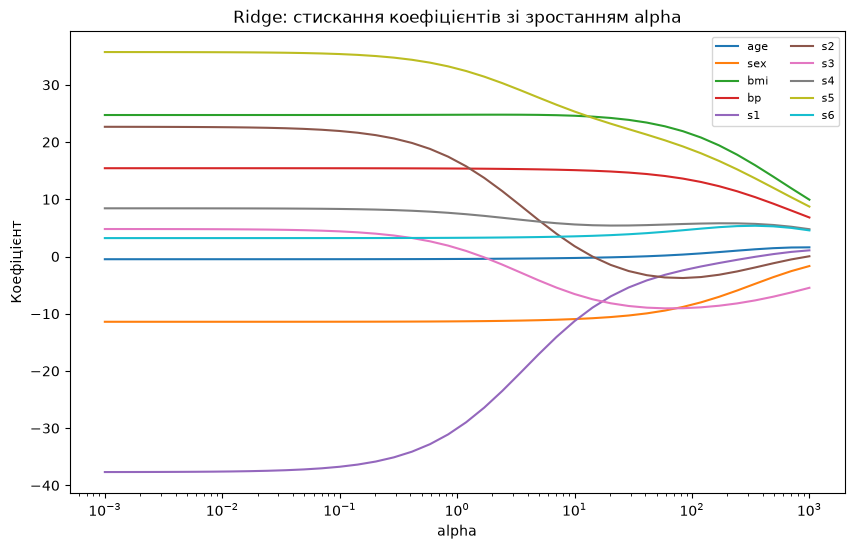

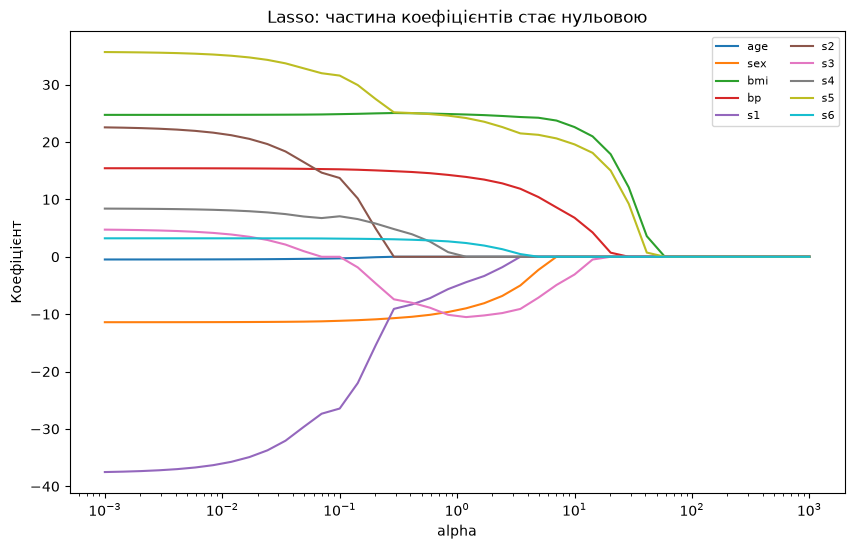

In [ ]:
alphas = np.logspace(-3, 3, 40)
ridge_paths = []
lasso_paths = []

X_for_path = StandardScaler().fit_transform(X)

for alpha in alphas:
    ridge_m = Ridge(alpha=alpha).fit(X_for_path, y)
    lasso_m = Lasso(alpha=alpha, max_iter=30000).fit(X_for_path, y)
    ridge_paths.append(ridge_m.coef_)
    lasso_paths.append(lasso_m.coef_)

ridge_paths = np.array(ridge_paths)
lasso_paths = np.array(lasso_paths)

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, ridge_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Ridge: стискання коефіцієнтів зі зростанням alpha')
plt.legend(ncol=2, fontsize=8)
plt.show()

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, lasso_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Lasso: частина коефіцієнтів стає нульовою')
plt.legend(ncol=2, fontsize=8)
plt.show()

Ці графіки демонструють ключову різницю. Ridge плавно стискає коефіцієнти до нуля, тоді як Lasso може зробити частину з них точно нульовими.

## 17. Мультиколінеарність і стабільність коефіцієнтів

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
n = 250
x1 = rng.normal(size=n)
x2 = x1 + rng.normal(scale=0.03, size=n)  # дуже сильна кореляція
x3 = rng.normal(size=n)
y_corr = 5 * x1 + 5 * x2 + 0.5 * x3 + rng.normal(scale=1.5, size=n)

X_corr = pd.DataFrame({'x1': x1, 'x2': x2, 'x3': x3})
print(X_corr.corr())

ols_corr = LinearRegression().fit(X_corr, y_corr)
ridge_corr = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(X_corr, y_corr)

coef_compare = pd.DataFrame({
    'feature': X_corr.columns,
    'OLS': ols_corr.coef_,
    'Ridge_scaled': ridge_corr.named_steps['reg'].coef_,
})
coef_compare

          x1        x2        x3
x1  1.000000  0.999515 -0.008921
x2  0.999515  1.000000 -0.010420
x3 -0.008921 -0.010420  1.000000


,feature,OLS,Ridge_scaled
0,x1,5.446248,4.546617
1,x2,4.410887,4.534370
2,x3,0.444792,0.439193


За наявності дуже корельованих ознак окремі коефіцієнти OLS можуть бути нестабільними: невеликі зміни даних здатні суттєво змінити їх значення. Ridge зменшує variance коефіцієнтів завдяки L2-штрафу.

## 18. Категоріальні ознаки, пропуски та ColumnTransformer

У реальній табличній задачі дані часто містять числові й категоріальні ознаки, а також пропуски. Їх потрібно обробляти всередині `Pipeline`, щоб не створювати витік інформації.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
n = 300

housing = pd.DataFrame({
    'area': rng.normal(75, 20, n).clip(25, 150),
    'rooms': rng.integers(1, 6, n),
    'age': rng.integers(0, 70, n).astype(float),
    'district': rng.choice(['center', 'north', 'south'], n, p=[0.3, 0.35, 0.35]),
})

# Додаємо кілька пропусків.
housing.loc[rng.choice(n, 18, replace=False), 'age'] = np.nan

price = (
    1500 * housing['area']
    + 7000 * housing['rooms']
    - 500 * housing['age'].fillna(housing['age'].median())
    + housing['district'].map({'center': 40000, 'north': 12000, 'south': 0})
    + rng.normal(0, 12000, n)
)

X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    housing, price, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = ['area', 'rooms', 'age']
categorical_features = ['district']

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])

housing_model = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=1.0)),
])

housing_model.fit(X_h_train, y_h_train)
housing_pred = housing_model.predict(X_h_test)

print('Housing RMSE:', root_mean_squared_error(y_h_test, housing_pred))
print('Housing R2:', r2_score(y_h_test, housing_pred))
print('Housing MAE:', mean_absolute_error(y_h_test, housing_pred))
print('MAPE', mean_absolute_percentage_error(y_h_test, housing_pred))

Housing RMSE: 10925.27837150393
Housing R2: 0.9068908686435069
Housing MAE: 8737.023097309468
MAPE 0.0727644013524896


### Самостійне завдання 7

Додайте до таблиці `housing` нову категоріальну ознаку `condition` зі значеннями `new`, `good`, `needs_repair`. Включіть її в `ColumnTransformer`, перенавчіть модель і перевірте, чи змінилася test-помилка.

In [ ]:
housing_c = housing.copy()
housing_c['condition'] = rng.choice(['new', 'good', 'needs_repair'], len(housing_c), p=[0.3, 0.4, 0.3])

# зробила так, щоб стан квартири впливав на ціну
price_c = price + housing_c['condition'].map({'new': 10000, 'good': 0, 'needs_repair': -15000})

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    housing_c, price_c, test_size=0.2, random_state=RANDOM_STATE
)

# модель без condition
model_old = Pipeline([
    ('prep', ColumnTransformer([
        ('num', numeric_pipe, numeric_features),
        ('cat', categorical_pipe, ['district']),
    ])),
    ('reg', Ridge(alpha=1.0)),
])
model_old.fit(Xc_train, yc_train)

# модель з condition
model_new = Pipeline([
    ('prep', ColumnTransformer([
        ('num', numeric_pipe, numeric_features),
        ('cat', categorical_pipe, ['district', 'condition']),
    ])),
    ('reg', Ridge(alpha=1.0)),
])
model_new.fit(Xc_train, yc_train)

print('Без condition: RMSE =', round(root_mean_squared_error(yc_test, model_old.predict(Xc_test))),
      ' R2 =', round(r2_score(yc_test, model_old.predict(Xc_test)), 3))
print('З condition:   RMSE =', round(root_mean_squared_error(yc_test, model_new.predict(Xc_test))),
      ' R2 =', round(r2_score(yc_test, model_new.predict(Xc_test)), 3))

Без condition: RMSE = 15512  R2 = 0.823
З condition:   RMSE = 11115  R2 = 0.909


**Висновок.**
Додала condition і зробила так, щоб вона впливала на ціну: нова квартира дорожча на 10 000, а та, що потребує ремонту, дешевша на 15 000.

- Без condition: RMSE 15 512, R² 0.823
- З condition: RMSE 11 115, R² 0.909

Помилка помітно зменшилась, бо модель тепер враховує стан квартири. Додати ознаку було просто: я тільки дописала її в список категоріальних ознак у ColumnTransformer.

## 19. Навчальні криві

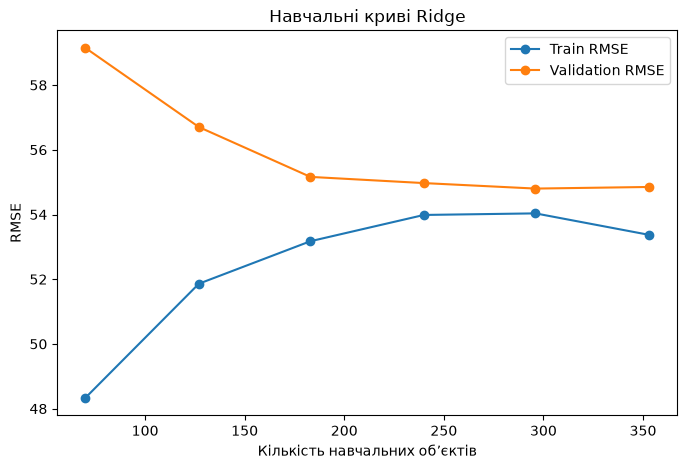

In [ ]:
learning_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=ridge_search.best_params_['reg__alpha'])),
])

train_sizes, train_scores, val_scores = learning_curve(
    learning_model,
    X,
    y,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
)

train_rmse_curve = -train_scores.mean(axis=1)
val_rmse_curve = -val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse_curve, marker='o', label='Train RMSE')
plt.plot(train_sizes, val_rmse_curve, marker='o', label='Validation RMSE')
plt.xlabel('Кількість навчальних об’єктів')
plt.ylabel('RMSE')
plt.title('Навчальні криві Ridge')
plt.legend()
plt.show()

Якщо train і validation помилки високі та близькі, це ознака можливого недонавчання. Якщо train-помилка значно нижча за validation, це може свідчити про високу variance та перенавчання. Навчальні криві допомагають зрозуміти, чи може збільшення обсягу даних бути корисним.

## 20. Повний приклад: коректний вибір моделі без використання test

In [ ]:
# 1. Test відкладаємо один раз.
X_final_train, X_final_test, y_final_train, y_final_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# 2. Вибір моделі відбувається тільки всередині train за CV.
model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.5, 0.9],
}

search = GridSearchCV(
    model,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
)
search.fit(X_final_train, y_final_train)

# 3. Лише після завершення підбору оцінюємо test.
final_pred = search.predict(X_final_test)

print('Найкращі параметри:', search.best_params_)
print('CV RMSE:', -search.best_score_)
print('Test metrics:', regression_metrics(y_final_test, final_pred))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test metrics: {'MAE': 42.81393247843441, 'MSE': 2888.4712888244917, 'RMSE': 53.74450007977087, 'R2': 0.4548152967432052, 'MAPE': np.float64(37.42858410670238)}


# 21. Підсумкове практичне завдання для самостійної роботи

Виконайте повний експеримент на наборі `diabetes`. Цей блок потрібно зробити **самостійно**, використовуючи попередні приклади лише як орієнтир.

Вимоги до роботи:

1. Завантажити `load_diabetes(as_frame=True)` і переглянути структуру даних.
2. Відкласти 20% даних у test із `random_state=42`.
3. Побудувати `DummyRegressor` і `LinearRegression` як baseline.
4. Обчислити MAE, RMSE та $R^2$ на test.
5. Побудувати Ridge, Lasso та Elastic Net через `Pipeline` із `StandardScaler`.
6. Виконати 5-fold cross-validation.
7. Для Ridge і Lasso підібрати `alpha`; для Elastic Net — `alpha` та `l1_ratio`.
8. Порівняти моделі в одній таблиці.
9. Для найкращої моделі побудувати графік `фактичні значення → прогноз` та графік залишків.
10. Проаналізувати коефіцієнти найкращої лінійної моделі.
11. Сформулювати підсумковий висновок: яка модель обрана, за якою метрикою та чому.

Нижче залишені окремі комірки для кожного етапу.

### Крок 1. Дані

In [ ]:
diabetes_task = load_diabetes(as_frame=True)
X_task = diabetes_task.data.copy()
y_task = diabetes_task.target.copy()

print('Розмір X:', X_task.shape)
print('Пропусків:', X_task.isna().sum().sum())
print(y_task.describe())
X_task.head()

Розмір X: (442, 10)
Пропусків: 0
count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


**Висновок.**
442 пацієнти, 10 ознак, пропусків немає. Цільова змінна від 25 до 346, середнє близько 152.

### Крок 2. Train/test

In [ ]:
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    X_task, y_task, test_size=0.2, random_state=42
)
print('train:', len(Xt_train), 'test:', len(Xt_test))

train: 353 test: 89


**Висновок.**
Train 353 об'єкти, test 89. Test використовую тільки в кінці.

### Крок 3. Baseline

In [ ]:
dummy_t = DummyRegressor(strategy='mean').fit(Xt_train, yt_train)
lr_t = LinearRegression().fit(Xt_train, yt_train)
print('моделі навчені')

моделі навчені


**Висновок.**
Dummy прогнозує середнє значення і потрібна для порівняння. LinearRegression враховує всі 10 ознак.

### Крок 4. Метрики

In [ ]:
dummy_pred_t = dummy_t.predict(Xt_test)
lr_pred_t = lr_t.predict(Xt_test)

table_base = pd.DataFrame({
    'MAE': [mean_absolute_error(yt_test, dummy_pred_t), mean_absolute_error(yt_test, lr_pred_t)],
    'RMSE': [root_mean_squared_error(yt_test, dummy_pred_t), root_mean_squared_error(yt_test, lr_pred_t)],
    'R2': [r2_score(yt_test, dummy_pred_t), r2_score(yt_test, lr_pred_t)],
}, index=['Dummy', 'LinearRegression'])
table_base.round(3)

,MAE,RMSE,R2
Dummy,64.006,73.222,-0.012
LinearRegression,42.794,53.853,0.453


**Висновок.**
| | MAE | RMSE | R² |
|---|---|---|---|
| Dummy | 64.0 | 73.2 | -0.01 |
| LinearRegression | 42.8 | 53.9 | 0.45 |

Лінійна регресія набагато краща за Dummy, в середньому помиляється приблизно на 43.

### Крок 5. Ridge, Lasso, Elastic Net

In [ ]:
ridge_t = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])
lasso_t = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(alpha=0.5, max_iter=30000)),
])
enet_t = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=30000)),
])

**Висновок.**
Зробила три моделі з регуляризацією через Pipeline зі StandardScaler. Без масштабування штраф діяв би на ознаки по-різному через різні одиниці виміру.

### Крок 6. Крос-валідація

In [ ]:
cv_t = KFold(n_splits=5, shuffle=True, random_state=0)

cv_models = {
    'Dummy': DummyRegressor(strategy='mean'),
    'LinearRegression': LinearRegression(),
    'Ridge': ridge_t,
    'Lasso': lasso_t,
    'ElasticNet': enet_t,
}

cv_result = []
for name in cv_models:
    s = cross_validate(cv_models[name], Xt_train, yt_train, cv=cv_t,
                       scoring='neg_root_mean_squared_error', return_train_score=True)
    cv_result.append({'model': name,
                      'train_RMSE': -s['train_score'].mean(),
                      'CV_RMSE': -s['test_score'].mean()})

cv_df = pd.DataFrame(cv_result)
cv_df.round(2)

,model,train_RMSE,CV_RMSE
0,Dummy,77.92,78.17
1,LinearRegression,53.40,54.94
2,Ridge,53.43,54.86
3,Lasso,53.62,54.89
4,ElasticNet,53.67,54.84


**Висновок.**
5-fold крос-валідація на train (KFold з random_state=0). CV RMSE:
- Dummy: 78.2
- LinearRegression: 54.9
- Ridge: 54.9
- Lasso: 54.9
- ElasticNet: 54.8

Лінійні моделі майже не відрізняються. Train RMSE близько 53.4-53.7, CV RMSE близько 54.9, різниця невелика, перенавчання немає.

### Крок 7. Підбір гіперпараметрів

In [ ]:
# Ridge
ridge_gs = GridSearchCV(ridge_t, {'reg__alpha': [0.1, 1, 5, 10, 50]},
                        cv=cv_t, scoring='neg_root_mean_squared_error')
ridge_gs.fit(Xt_train, yt_train)
print('Ridge best:', ridge_gs.best_params_, ' CV RMSE:', round(-ridge_gs.best_score_, 2))

# Lasso
lasso_gs = GridSearchCV(lasso_t, {'reg__alpha': [0.001, 0.01, 0.1, 0.3, 1]},
                        cv=cv_t, scoring='neg_root_mean_squared_error')
lasso_gs.fit(Xt_train, yt_train)
print('Lasso best:', lasso_gs.best_params_, ' CV RMSE:', round(-lasso_gs.best_score_, 2))

# ElasticNet
enet_gs = GridSearchCV(enet_t, {'reg__alpha': [0.01, 0.05, 0.1, 0.5],
                                'reg__l1_ratio': [0.3, 0.5, 0.7, 1.0]},
                       cv=cv_t, scoring='neg_root_mean_squared_error')
enet_gs.fit(Xt_train, yt_train)
print('ElasticNet best:', enet_gs.best_params_, ' CV RMSE:', round(-enet_gs.best_score_, 2))

Ridge best: {'reg__alpha': 5}  CV RMSE: 54.83
Lasso best: {'reg__alpha': 0.3}  CV RMSE: 54.88


ElasticNet best: {'reg__alpha': 0.05, 'reg__l1_ratio': 0.7}  CV RMSE: 54.83


**Висновок.**
Результати GridSearchCV:
- Ridge: alpha = 5, CV RMSE 54.83
- Lasso: alpha = 0.3, CV RMSE 54.88
- ElasticNet: alpha = 0.05, l1_ratio = 0.7, CV RMSE 54.83

Ridge і ElasticNet майже однакові, Lasso трохи гірше.

### Крок 8. Фінальна таблиця моделей

In [ ]:
# для Dummy і LinearRegression CV RMSE беру з кроку 6, для інших з GridSearchCV
cv_dummy = cv_df.loc[cv_df['model'] == 'Dummy', 'CV_RMSE'].values[0]
cv_lr = cv_df.loc[cv_df['model'] == 'LinearRegression', 'CV_RMSE'].values[0]

all_models = {
    'Dummy': (dummy_t, cv_dummy),
    'LinearRegression': (lr_t, cv_lr),
    'Ridge': (ridge_gs.best_estimator_, -ridge_gs.best_score_),
    'Lasso': (lasso_gs.best_estimator_, -lasso_gs.best_score_),
    'ElasticNet': (enet_gs.best_estimator_, -enet_gs.best_score_),
}

final_rows = []
for name in all_models:
    m, cv_rmse = all_models[name]
    p = m.predict(Xt_test)
    final_rows.append([name, cv_rmse,
                       mean_absolute_error(yt_test, p),
                       root_mean_squared_error(yt_test, p),
                       r2_score(yt_test, p)])

final_table = pd.DataFrame(final_rows, columns=['model', 'CV_RMSE', 'test_MAE', 'test_RMSE', 'test_R2'])
final_table = final_table.sort_values('CV_RMSE')
final_table.round(3)

,model,CV_RMSE,test_MAE,test_RMSE,test_R2
2,Ridge,54.826,42.841,53.679,0.456
4,ElasticNet,54.829,42.845,53.658,0.457
3,Lasso,54.882,42.852,53.601,0.458
1,LinearRegression,54.944,42.794,53.853,0.453
0,Dummy,78.172,64.006,73.222,-0.012


**Висновок.**

| Модель | CV RMSE | test MAE | test RMSE | test R² |
|---|---|---|---|---|
| Ridge | 54.83 | 42.84 | 53.68 | 0.456 |
| ElasticNet | 54.83 | 42.85 | 53.66 | 0.457 |
| Lasso | 54.88 | 42.85 | 53.60 | 0.458 |
| LinearRegression | 54.94 | 42.79 | 53.85 | 0.453 |
| Dummy | 78.17 | 64.01 | 73.22 | -0.012 |

Обирала за CV RMSE, тому найкраща модель Ridge з alpha = 5. На test Lasso трохи кращий, але за test модель не обирають.

### Крок 9. Візуалізація найкращої моделі

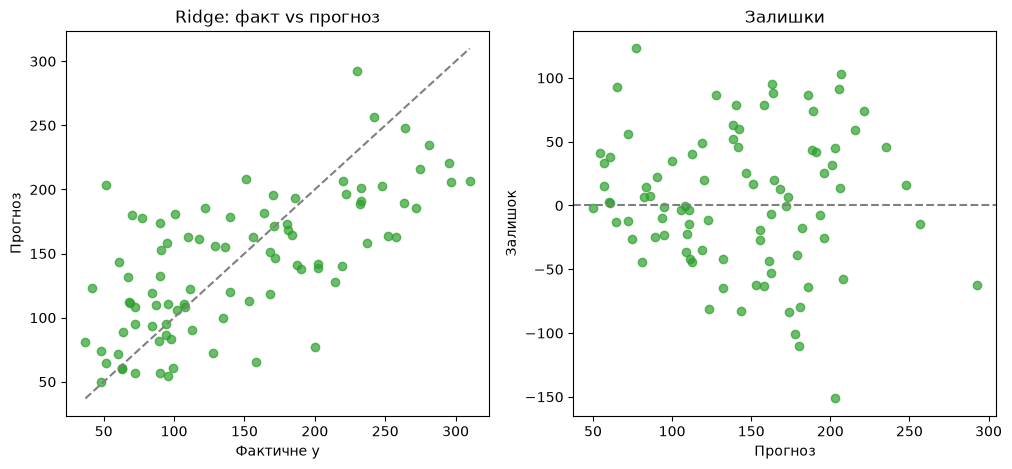

In [ ]:
best_model = ridge_gs.best_estimator_
best_pred = best_model.predict(Xt_test)
resid = yt_test - best_pred

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(yt_test, best_pred, alpha=0.7, color='tab:green')
ax[0].plot([yt_test.min(), yt_test.max()], [yt_test.min(), yt_test.max()], '--', color='gray')
ax[0].set_xlabel('Фактичне y')
ax[0].set_ylabel('Прогноз')
ax[0].set_title('Ridge: факт vs прогноз')

ax[1].scatter(best_pred, resid, alpha=0.7, color='tab:green')
ax[1].axhline(0, linestyle='--', color='gray')
ax[1].set_xlabel('Прогноз')
ax[1].set_ylabel('Залишок')
ax[1].set_title('Залишки')

plt.show()

**Висновок.**
Точки на графіку «факт vs прогноз» розташовані вздовж діагоналі, але з великим розкидом. Модель тягне прогнози до середнього: великі значення занижує, малі завищує.

Залишки розкидані навколо нуля без явної форми, тому лінійна модель підходить, але помилки досить великі.

### Крок 10. Коефіцієнти

In [ ]:
coef_df = pd.DataFrame({
    'feature': X_task.columns,
    'coefficient': best_model.named_steps['reg'].coef_.round(2),
})
coef_df = coef_df.sort_values('coefficient', key=abs, ascending=False)
display(coef_df)

print('Коефіцієнтів, рівних нулю:', (coef_df['coefficient'] == 0).sum())

,feature,coefficient
2,bmi,25.78
8,s5,25.31
4,s1,-19.20
3,bp,16.50
1,sex,-11.25
7,s4,9.53
5,s2,5.18
6,s3,-3.42
9,s6,2.71
0,age,1.89


Коефіцієнтів, рівних нулю: 0


**Висновок.**
Найбільший вплив у моделі Ridge мають:
- bmi: +25.8
- s5: +25.3
- s1: -19.2
- bp: +16.5

Наприклад, якщо bmi зросте на одне стандартне відхилення, прогноз зросте приблизно на 26. Ridge не зануляє коефіцієнти, тому всі 10 ознак залишились у моделі, а найменший вплив у age і s6.

### Крок 11. Підсумковий висновок

У новій Markdown-комірці після цієї сформулюйте висновок обсягом 5–8 речень. Обов'язково зазначте:

- яка модель показала найкращий результат;
- за якою метрикою виконано вибір;
- чи є ознаки перенавчання;
- як регуляризація вплинула на результат;
- чому test не використовувався під час підбору гіперпараметрів.

**Підсумковий висновок.**
Найкращою за CV RMSE вийшла модель Ridge з alpha = 5 (CV RMSE 54.83). На test вона дала RMSE 53.7, MAE 42.8 і R² 0.456.

Ознак перенавчання немає: train RMSE близько 53.4, CV RMSE близько 54.8.

Регуляризація покращила результат зовсім трохи, CV RMSE зменшився лише на 0.1 порівняно зі звичайною регресією. Найважливіші ознаки: bmi, s5, s1 і bp.

Test не використовувала під час підбору гіперпараметрів, щоб він залишився незалежною перевіркою моделі на нових даних.

## Контрольні питання після практики

1. Чому `StandardScaler` для Ridge/Lasso/Elastic Net доцільно розміщувати всередині `Pipeline`?
2. Чим відрізняється train-помилка від validation/test-помилки?
3. За якими ознаками можна розпізнати перенавчання?
4. Чим L1-регуляризація відрізняється від L2-регуляризації?
5. Чому `alpha` не можна підбирати за тестовою вибіркою?
6. Яку роль відіграє `l1_ratio` в Elastic Net?
7. Чому великий за модулем коефіцієнт не завжди означає, що ознака є найважливішою?
8. У чому перевага крос-валідації порівняно з одним випадковим validation-розбиттям?

**Відповіді на контрольні питання**

1. Тоді середнє і стандартне відхилення рахуються тільки на train, і інформація з test не потрапляє в модель.

2. Train-помилка показує, як модель працює на знайомих даних, а validation/test-помилка на нових.

3. Якщо train-помилка набагато менша за validation/test-помилку, або якщо при ускладненні моделі test-помилка починає рости.

4. L1 штрафує суму модулів коефіцієнтів і може занулювати їх, L2 штрафує суму квадратів і тільки зменшує коефіцієнти.

5. Бо модель підлаштується під test, і фінальна оцінка буде завищеною.

6. Він визначає, яка частина штрафу L1, а яка L2.

7. Бо він залежить від одиниць виміру ознаки і від кореляції з іншими ознаками.

8. Результат усереднюється по кількох розбиттях, тому він стабільніший і менше залежить від випадку.